<a href="https://colab.research.google.com/github/matashova12345/Application-Deployment/blob/main/MatashovaViktoriia_26.10.02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

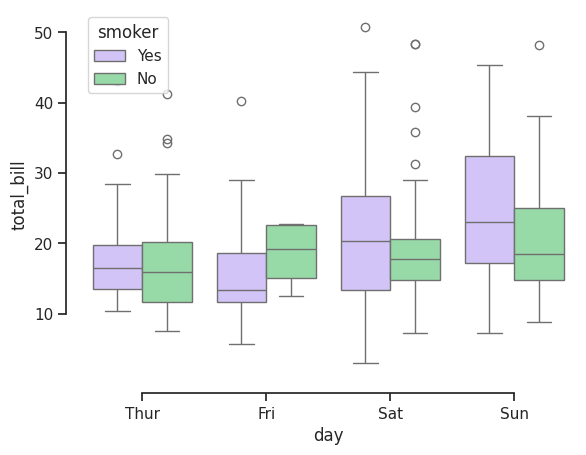

In [1]:
import seaborn as sns
sns.set_theme(style="ticks", palette="pastel")

# Load the example tips dataset
tips = sns.load_dataset("tips")

# Draw a nested boxplot to show bills by day and time
sns.boxplot(x="day", y="total_bill",
            hue="smoker", palette=["m", "g"],
            data=tips)
sns.despine(offset=10, trim=True)

# EDA(Exponatory)
feature

In [3]:
tips.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [4]:
# df = tips
df = tips.copy()

In [5]:
%whos

Variable   Type         Data/Info
---------------------------------
df         DataFrame         total_bill   tip    <...>n\n[244 rows x 7 columns]
sns        module       <module 'seaborn' from '/<...>ges/seaborn/__init__.py'>
tips       DataFrame         total_bill   tip    <...>n\n[244 rows x 7 columns]


In [6]:
df['tip_pct'] = (df['tip'] / df['total_bill']) * 100
result = df[(df['tip_pct'] >= 20) & ((df['day'] == 'Sat') | (df['day'] == 'Sun'))]

In [13]:
df[df['tip_pct'] >= 20]

,total_bill,tip,sex,smoker,day,time,size,tip_pct
6,8.77,2.00,Male,No,Sun,Dinner,2,22.805017
9,14.78,3.23,Male,No,Sun,Dinner,2,21.853857
14,14.83,3.02,Female,No,Sun,Dinner,2,20.364127
17,16.29,3.71,Male,No,Sun,Dinner,3,22.774708
18,16.97,3.50,Female,No,Sun,Dinner,3,20.624632
20,17.92,4.08,Male,No,Sat,Dinner,2,22.767857
42,13.94,3.06,Male,No,Sun,Dinner,2,21.951220
46,22.23,5.00,Male,No,Sun,Dinner,2,22.492128
51,10.29,2.60,Female,No,Sun,Dinner,2,25.267250
63,18.29,3.76,Male,Yes,Sat,Dinner,4,20.557682


In [8]:
(df['tip'] / df['total_bill']) * 100

,0
0,5.944673
1,16.054159
2,16.658734
3,13.978041
4,14.680765
...,...
239,20.392697
240,7.358352
241,8.822232
242,9.820426


In [16]:
tips

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [17]:
id(df)

138347475947824

In [18]:
id(tips)

138347526741968

## >> Prompt : 이 데이터 범주형과 수치형데이터 단변량 분석하는 시각화와 두개, 두개이상의 다변령 분석 시각화를 seaborn 코드로 주라

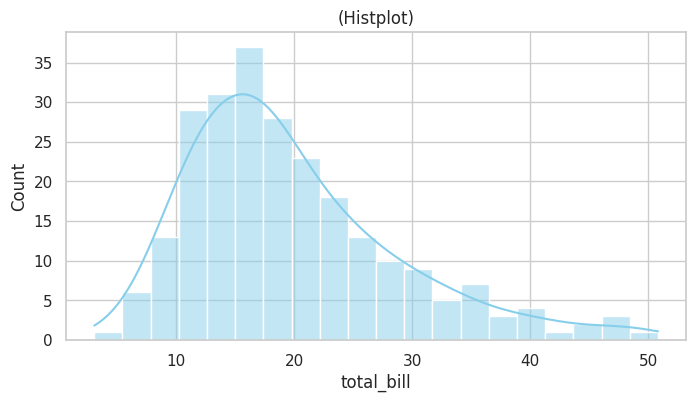

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))
# total_bill의 분포 확인 (kde=True로 부드러운 곡선 추가)
sns.histplot(data=tips, x="total_bill", kde=True, bins=20, color="skyblue")
plt.title("(Histplot)")
plt.show()

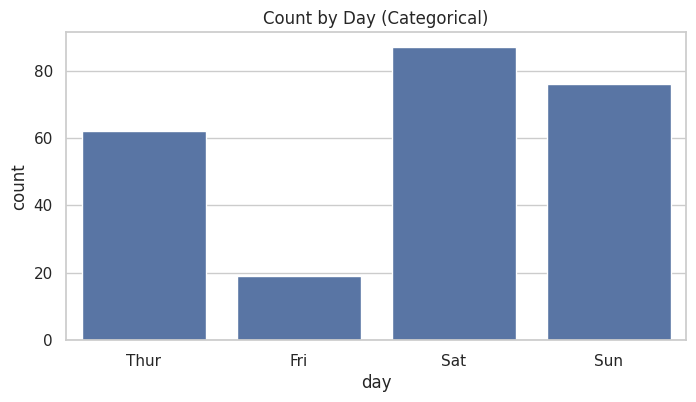

In [21]:
# @title (2) 범주형 변수 단변량: day 요일별 방문 빈도 (Count Plot)
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='day')
plt.title("Count by Day (Categorical)")
plt.show()

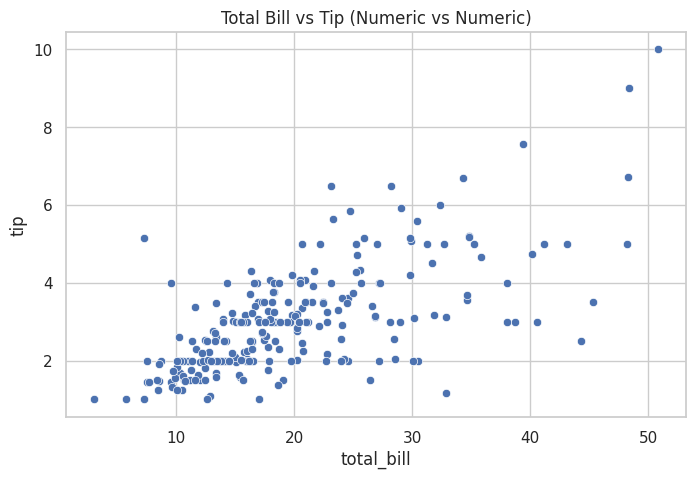

In [22]:
# @title (1) 수치형 vs 수치형: total_bill과 tip의 관계 (Scatter Plot)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='total_bill', y='tip')
plt.title("Total Bill vs Tip (Numeric vs Numeric)")
plt.show()

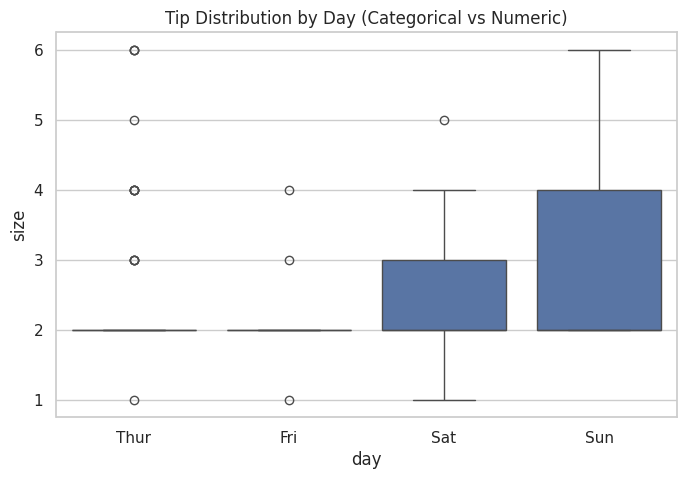

In [29]:
# @title (2) 범주형 vs 수치형: day별 tip 분포 비교 (Box Plot)
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='day', y='size')
plt.title("Tip Distribution by Day (Categorical vs Numeric)")
plt.show()

In [31]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [30]:
df.groupby('day').describe()

/tmp/ipykernel_1591/1891411268.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('day').describe()


total_bill                                                             \
          count       mean       std   min      25%    50%      75%    max   
day                                                                          
Thur       62.0  17.682742  7.886170  7.51  12.4425  16.20  20.1550  43.11   
Fri        19.0  17.151579  8.302660  5.75  12.0950  15.38  21.7500  40.17   
Sat        87.0  20.441379  9.480419  3.07  13.9050  18.24  24.7400  50.81   
Sun        76.0  21.410000  8.832122  7.25  14.9875  19.63  25.5975  48.17   

       tip            ...                 size                                \
     count      mean  ...     75%    max count      mean       std  min  25%   
day                   ...                                                      
Thur  62.0  2.771452  ...  3.3625   6.70  62.0  2.451613  1.066285  1.0  2.0   
Fri   19.0  2.734737  ...  3.3650   4.73  19.0  2.105263  0.567131  1.0  2.0   
Sat   87.0  2.993103  ...  3.3700  10.00  87.0  2.517241  0.819275  1.0  2.0   
Sun   76.0  3.255132  ...  4.0000   6.50  76.0  2.842105  1.007341  2.0  2.0   

                     
      50%  75%  max  
day                  
Thur  2.0  2.0  6.0  
Fri   2.0  2.0  4.0  
Sat   2.0  3.0  5.0  
Sun   2.0  4.0  6.0  

[4 rows x 24 columns]

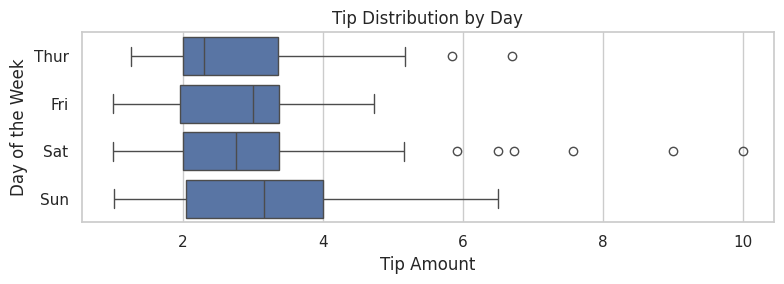

In [32]:
plt.figure(figsize=(8, 3))
sns.boxplot(data=df, x='tip', y='day')
plt.title("Tip Distribution by Day")
plt.xlabel("Tip Amount")
plt.ylabel("Day of the Week")
plt.tight_layout()
plt.show()

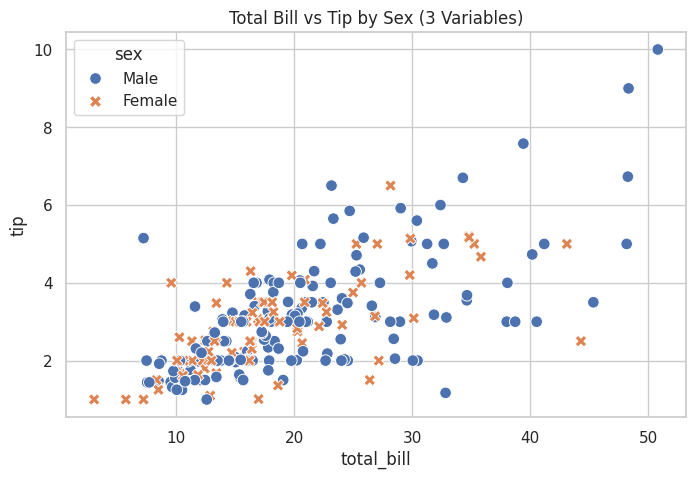

In [33]:
# @title (1) 수치형 2개 + 범주형 1개 (hue 활용): total_bill과 tip 관계를 sex별로 구분
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='total_bill', y='tip', hue='sex', style='sex', s=70)
plt.title("Total Bill vs Tip by Sex (3 Variables)")
plt.show()